# 02 - Baseline model: Roman Urdu sentiment
Goal: first real ML result. TF-IDF + Linear SVM, with and without the normalizer, using word and character n-grams.

**Run cells top to bottom (Shift + Enter).**

In [1]:
import sys; sys.path.append('..')
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from src.normalizer import normalize

RAW = Path('../data/raw')
DOCS = Path('../docs')

## 1. Load and clean
Duplicate texts are removed **before** splitting. Otherwise the same text can be in both train and test, and the score looks better than it really is (data leakage).

In [2]:
ru = pd.read_csv(RAW / 'roman_urdu.csv', header=None, usecols=[0, 1],
                 names=['text', 'label'], on_bad_lines='skip').dropna(subset=['text'])
ru['label'] = ru['label'].str.strip().str.lower().replace({'neative': 'negative'})
ru['text'] = ru['text'].astype(str)

print('rows loaded      :', len(ru))
print('duplicate texts  :', ru['text'].duplicated().sum())
print('empty texts      :', (ru['text'].str.strip() == '').sum())

ru = ru[ru['text'].str.strip() != ''].drop_duplicates(subset='text')
print('rows after clean :', len(ru))
ru['label'].value_counts()

rows loaded      : 20228
duplicate texts  : 564
empty texts      : 112
rows after clean : 19626


label
neutral     8532
positive    5854
negative    5240
Name: count, dtype: int64

## 2. Train / test split (80 / 20, same labels ratio)

In [3]:
train, test = train_test_split(ru, test_size=0.2, stratify=ru['label'], random_state=42)
print('train:', len(train), ' test:', len(test))

train: 15700  test: 3926


## 3. Run 4 experiments
Same model (Linear SVM), different text features:
- **word** TF-IDF: whole words and word pairs
- **char** TF-IDF: groups of 2 to 5 letters (can handle spelling variants)
- each one **raw** and **normalized**

In [4]:
def run(name, vectorizer, use_norm):
    t0 = time.time()
    X_train = train['text'].map(normalize) if use_norm else train['text']
    X_test = test['text'].map(normalize) if use_norm else test['text']
    model = make_pipeline(vectorizer, LinearSVC(C=1.0, class_weight='balanced'))
    model.fit(X_train, train['label'])
    pred = model.predict(X_test)
    return {
        'experiment': name,
        'accuracy': round(accuracy_score(test['label'], pred), 3),
        'macro_f1': round(f1_score(test['label'], pred, average='macro'), 3),
        'seconds': round(time.time() - t0),
    }, pred

def word_vec():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

def char_vec():
    return TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True)

experiments = [
    ('word, raw text', word_vec, False),
    ('word, normalized', word_vec, True),
    ('char, raw text', char_vec, False),
    ('char, normalized', char_vec, True),
]

results, preds = [], {}
for name, make_vec, use_norm in experiments:
    row, pred = run(name, make_vec(), use_norm)
    results.append(row); preds[name] = pred
    print(row)

results_df = pd.DataFrame(results)
results_df.to_csv(DOCS / 'baseline_results.csv', index=False)
results_df

{'experiment': 'word, raw text', 'accuracy': 0.64, 'macro_f1': 0.632, 'seconds': 2}
{'experiment': 'word, normalized', 'accuracy': 0.641, 'macro_f1': 0.633, 'seconds': 5}
{'experiment': 'char, raw text', 'accuracy': 0.66, 'macro_f1': 0.653, 'seconds': 10}
{'experiment': 'char, normalized', 'accuracy': 0.658, 'macro_f1': 0.652, 'seconds': 12}


,experiment,accuracy,macro_f1,seconds
0,"word, raw text",0.640,0.632,2
1,"word, normalized",0.641,0.633,5
2,"char, raw text",0.660,0.653,10
3,"char, normalized",0.658,0.652,12


## 4. Best model: detailed report

Best experiment: char, raw text

              precision    recall  f1-score   support

    negative       0.62      0.60      0.61      1048
     neutral       0.69      0.70      0.70      1707
    positive       0.66      0.65      0.65      1171

    accuracy                           0.66      3926
   macro avg       0.65      0.65      0.65      3926
weighted avg       0.66      0.66      0.66      3926



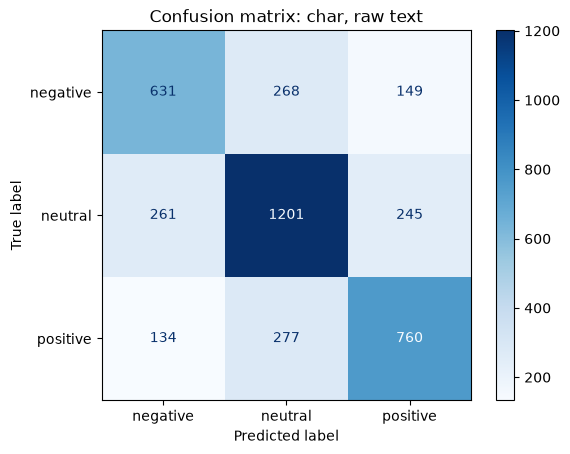

In [5]:
best = results_df.sort_values('macro_f1', ascending=False).iloc[0]['experiment']
print('Best experiment:', best)
print()
print(classification_report(test['label'], preds[best]))

ConfusionMatrixDisplay.from_predictions(test['label'], preds[best], cmap='Blues')
plt.title(f'Confusion matrix: {best}')
plt.show()

## 5. Error analysis
Look at mistakes with your own eyes. This is where thesis ideas come from.

In [6]:
errors = test.assign(predicted=preds[best])
errors = errors[errors['label'] != errors['predicted']]
print('Total mistakes:', len(errors), 'of', len(test))
pd.set_option('display.max_colwidth', 120)
errors.sample(15, random_state=1)[['text', 'label', 'predicted']]

Total mistakes: 1334 of 3926


,text,label,predicted
6032,Team se un ke drop hone ka jan kar heran howe aur unhen Pakistani team mein shamil kar liya to 4 wickets le kar apna...,neutral,positive
12105,Seth chotani ko angrezon ne apni resha dawaniyon aur sarkari aehkamat ke zariye dewaliya kar diya aur wo is sadmey ...,negative,positive
19393,Boy InoXant Tera wala scene raat ka u knw,negative,neutral
1691,Wo bachpan se he bohat zaheen taliba thin aur sirf 12 baras ki umer mein inho ne Madras University ke matric ke imt...,positive,neutral
13113,Itna achha bhi ni ha aur na hi bura Read more Hide,neutral,negative
9649,Qatib e taqdeer sirf mera rub hy Os k elawa koi itni planned story likh he nahi Sakta.. Ye baat bilkul Theek hy k ma...,neutral,positive
14436,Mny dkhi hai ek larki k pasy dny hty hai eska dil nai krta dny do aazab wla khueab dkhti hai t pher amant pasy wps k...,neutral,negative
5369,Kal Youm e Ali RA Per Rangers Police K Sath Faraiz Anjam Degi,neutral,negative
3107,Jinhe 9 umri se he apne husun ka ehsaas ho jata hai,positive,neutral
10870,Quaid e Azam Muhammad Ali Jinah Ki Hamsheera Madir e Millat Fatima Jinah Ka Aj 48va Yom Wafat Manaya Ja Raha Hai,negative,positive


## My notes (write in your own words)
1. **Best experiment and score:** 
2. **Did normalization help? By how much?** 
3. **Which label is hardest (see confusion matrix)?** 
4. **Patterns in the mistakes (sarcasm, short texts, mixed English, wrong labels):** 

In [ ]:
# 1. Best experiment and score: The character-level TF-IDF model using raw text performed best, achieving 66.0% accuracy and 65.3% macro F1-score.

# 2. Did normalization help? By how much? Normalization helped the word-level model slightly, increasing accuracy from 64.0% to 64.1% and macro F1 from 63.2% to 63.3%. However, it slightly reduced the character-level model's accuracy from 66.0% to 65.8%.

# 3. Which label is hardest (see confusion matrix)? The negative label was the hardest to predict, with an F1-score of 0.61, compared with 0.70 for neutral and 0.65 for positive.

# 4. Patterns in the mistakes (sarcasm, short texts, mixed English, wrong labels): The model made mistakes on short texts, mixed English and Roman Urdu, informal spellings, emojis, and sentences whose sentiment was unclear. Some examples also contained news or factual statements that were difficult to classify. Sarcasm or incorrectly labeled data may also contribute, but these need further checking.